# Notebook 5 — Deep Learning Models

Architectures:
1. **CNN1D** on MFCC features
2. **LSTM** on sequential audio features
3. **CNN+LSTM** hybrid
4. **Spectrogram CNN** with ResNet18 / EfficientNetB0 transfer learning


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import torch
import matplotlib.pyplot as plt

from preprocessing import DataLoader, FeatureProcessor
from signal_generator import SignalGenerator
from audio_features import AudioFeatureExtractor
from models import (
    CNN1DClassifier, LSTMClassifier, CNNLSTMHybrid,
    SpectrogramCNN, ModelTrainer, create_dataloaders, DEVICE
)
from evaluate import Evaluator

FIG_DIR = '../reports/figures'
SAMPLE_SIZE = 1000
EPOCHS = 12
BATCH_SIZE = 32
RANDOM_STATE = 42

print(f"Device: {DEVICE}")


Device: cuda


In [2]:
# Data preparation
loader = DataLoader(data_dir='../data/raw')
train_df, test_df = loader.load_nsl_kdd(sample_size=SAMPLE_SIZE)

processor = FeatureProcessor()
X_train, y_train, _ = processor.prepare_features(train_df, fit=True)
X_test, y_test, _ = processor.prepare_features(test_df, fit=False)

from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train)

sig_gen = SignalGenerator()
sig_gen.fit(X_tr)
extractor = AudioFeatureExtractor()

# MFCC for CNN/LSTM
mfcc_train = extractor.extract_batch_mfcc(sig_gen.generate_batch(X_tr))
mfcc_val = extractor.extract_batch_mfcc(sig_gen.generate_batch(X_val))
mfcc_test = extractor.extract_batch_mfcc(sig_gen.generate_batch(X_test))

# Spectrograms for transfer learning
def to_specs(X):
    return np.array([sig_gen.signal_to_spectrogram_image(sig_gen.generate_signal(x)) for x in X])

spec_train = to_specs(X_tr)
spec_val = to_specs(X_val)
spec_test = to_specs(X_test)

# Normalize spectrograms
spec_mean, spec_std = spec_train.mean(), spec_train.std()
spec_train = (spec_train - spec_mean) / (spec_std + 1e-8)
spec_val = (spec_val - spec_mean) / (spec_std + 1e-8)
spec_test = (spec_test - spec_mean) / (spec_std + 1e-8)

print(f"MFCC shape: {mfcc_train.shape}")
print(f"Spec shape: {spec_train.shape}")


MFCC shape: (800, 20, 87)
Spec shape: (800, 128, 87)


In [3]:
evaluator = Evaluator(FIG_DIR)
dl_results = {}
histories = {}

# --- CNN1D ---
train_loader, val_loader = create_dataloaders(mfcc_train, y_tr, mfcc_val, y_val, BATCH_SIZE, 'mfcc')
cnn = CNN1DClassifier(n_mfcc=20, n_classes=2)
trainer = ModelTrainer(cnn)
histories['CNN1D'] = trainer.fit(train_loader, val_loader, epochs=EPOCHS)

test_loader, _ = create_dataloaders(mfcc_test, y_test, mfcc_test[:1], y_test[:1], BATCH_SIZE, 'mfcc')
y_pred, y_prob = trainer.predict(test_loader)
dl_results['CNN1D'] = evaluator.compute_metrics(y_test, y_pred, y_prob)
print(f"CNN1D F1: {dl_results['CNN1D']['f1']:.4f}")


CNN1D F1: 0.5651


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\notebooks\../src\models.py:30: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  self.labels = torch.LongTensor(labels)


In [4]:
# --- LSTM ---
train_loader, val_loader = create_dataloaders(mfcc_train, y_tr, mfcc_val, y_val, BATCH_SIZE, 'mfcc')
lstm = LSTMClassifier(input_size=20, n_classes=2)
trainer_lstm = ModelTrainer(lstm)
histories['LSTM'] = trainer_lstm.fit(train_loader, val_loader, epochs=EPOCHS)
y_pred, y_prob = trainer_lstm.predict(test_loader)
dl_results['LSTM'] = evaluator.compute_metrics(y_test, y_pred, y_prob)
print(f"LSTM F1: {dl_results['LSTM']['f1']:.4f}")


LSTM F1: 0.3862


In [5]:
# --- CNN+LSTM Hybrid ---
hybrid = CNNLSTMHybrid(n_mfcc=20, n_classes=2)
trainer_hybrid = ModelTrainer(hybrid)
histories['CNN+LSTM'] = trainer_hybrid.fit(train_loader, val_loader, epochs=EPOCHS)
y_pred, y_prob = trainer_hybrid.predict(test_loader)
dl_results['CNN+LSTM'] = evaluator.compute_metrics(y_test, y_pred, y_prob)
print(f"CNN+LSTM F1: {dl_results['CNN+LSTM']['f1']:.4f}")


CNN+LSTM F1: 0.5995


In [6]:
# --- Spectrogram CNN (ResNet18) ---
train_loader_s, val_loader_s = create_dataloaders(spec_train, y_tr, spec_val, y_val, BATCH_SIZE, 'spec')
test_loader_s, _ = create_dataloaders(spec_test, y_test, spec_test[:1], y_test[:1], BATCH_SIZE, 'spec')

resnet = SpectrogramCNN(backbone='resnet18', n_classes=2, pretrained=True)
trainer_resnet = ModelTrainer(resnet)
histories['ResNet18'] = trainer_resnet.fit(train_loader_s, val_loader_s, epochs=EPOCHS)
y_pred, y_prob = trainer_resnet.predict(test_loader_s)
dl_results['ResNet18'] = evaluator.compute_metrics(y_test, y_pred, y_prob)
print(f"ResNet18 F1: {dl_results['ResNet18']['f1']:.4f}")


ResNet18 F1: 0.3738


In [7]:
# --- EfficientNetB0 ---
effnet = SpectrogramCNN(backbone='efficientnet_b0', n_classes=2, pretrained=True)
trainer_eff = ModelTrainer(effnet)
histories['EfficientNetB0'] = trainer_eff.fit(train_loader_s, val_loader_s, epochs=EPOCHS)
y_pred, y_prob = trainer_eff.predict(test_loader_s)
dl_results['EfficientNetB0'] = evaluator.compute_metrics(y_test, y_pred, y_prob)
print(f"EfficientNetB0 F1: {dl_results['EfficientNetB0']['f1']:.4f}")


EfficientNetB0 F1: 0.4721


,accuracy,precision,recall,f1,roc_auc
CNN1D,0.509,0.5727,0.5577,0.5651,0.4978
LSTM,0.450,0.5340,0.3024,0.3862,0.4815
CNN+LSTM,0.519,0.5723,0.6294,0.5995,0.5137
ResNet18,0.464,0.5634,0.2797,0.3738,0.4895
EfficientNetB0,0.470,0.5486,0.4143,0.4721,0.4831


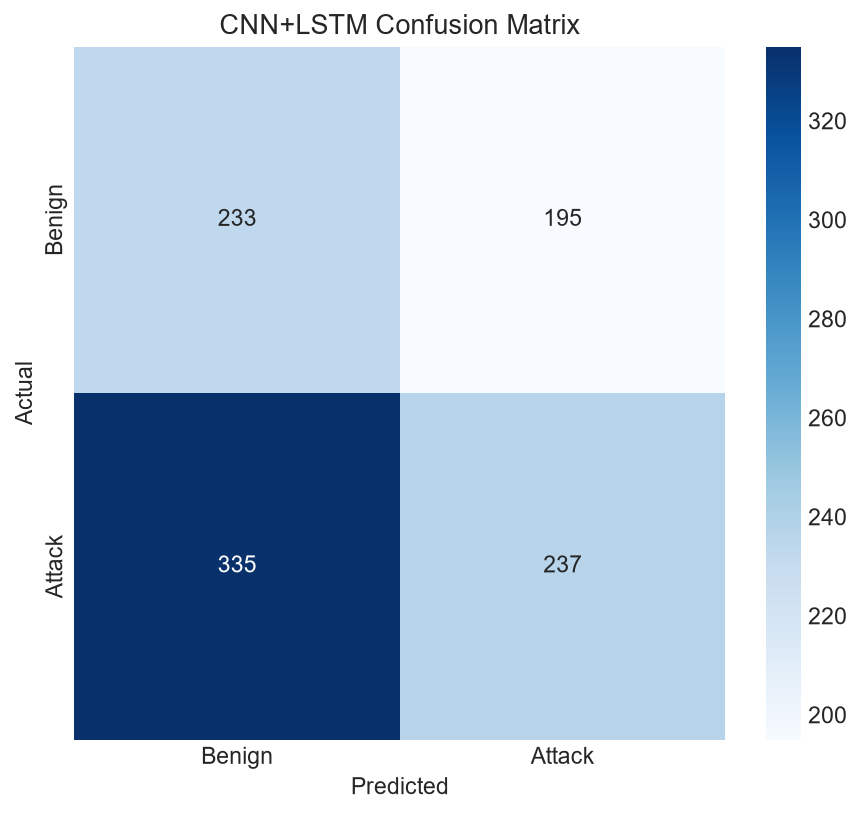

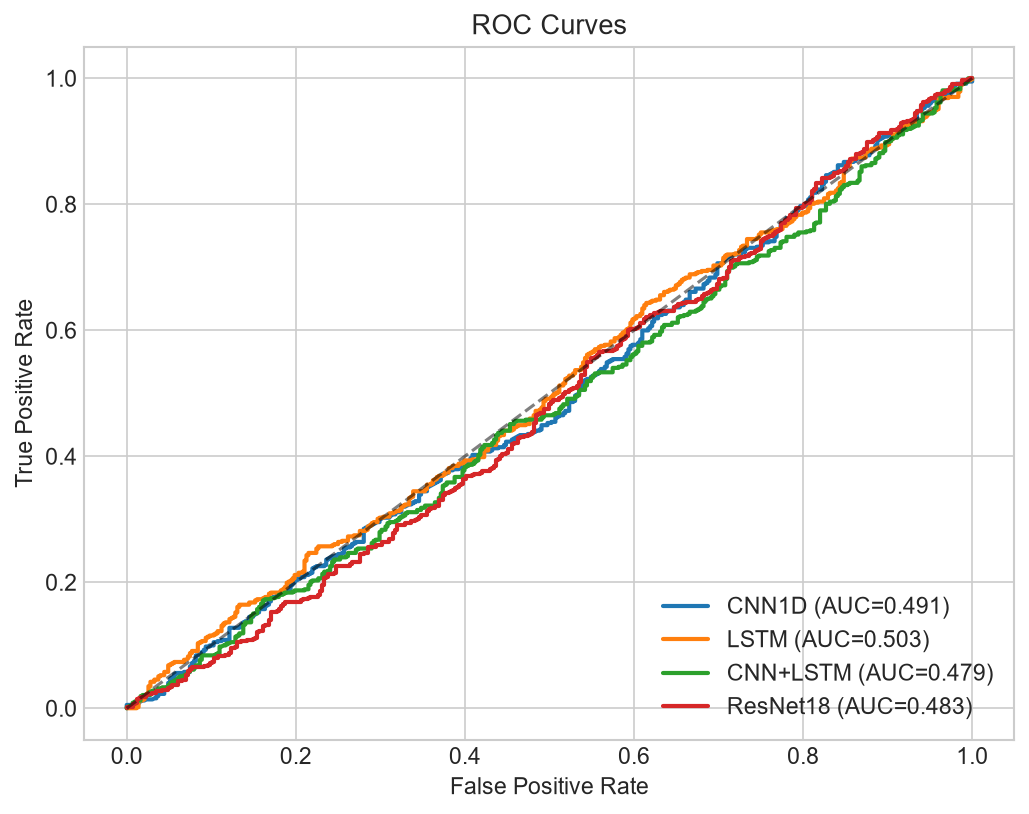

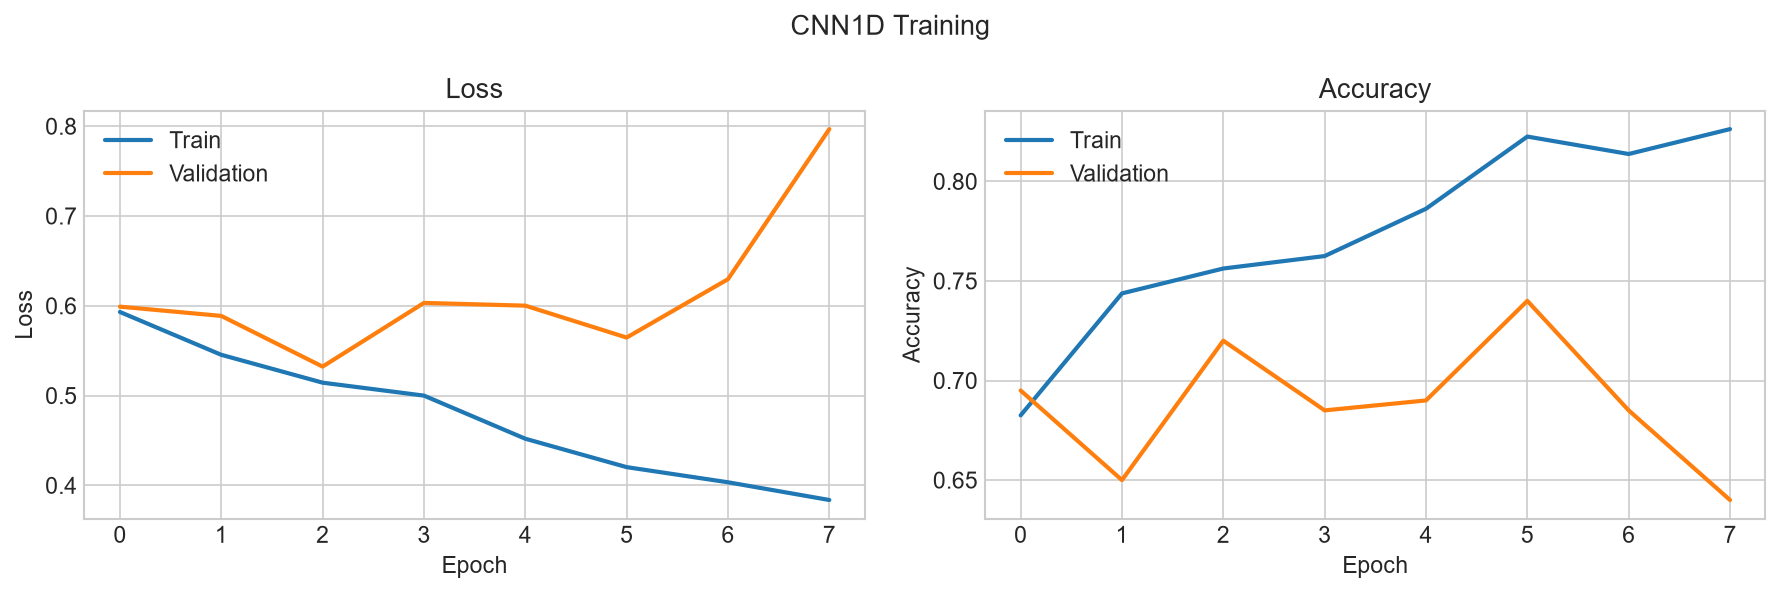

In [8]:
# Evaluation plots
display(evaluator.metrics_to_dataframe(dl_results))

# Confusion matrix for best model
best_model = max(dl_results, key=lambda k: dl_results[k]['f1'])
evaluator.plot_confusion_matrix(y_test, y_pred, title=f'{best_model} Confusion Matrix',
    save_path=f'{FIG_DIR}/16_confusion_matrix.png')
plt.show()

# ROC curves
roc_data = {}
for name, trainer_obj in [('CNN1D', trainer), ('LSTM', trainer_lstm), ('CNN+LSTM', trainer_hybrid)]:
    yp, ypr = trainer_obj.predict(test_loader)
    roc_data[name] = evaluator.get_roc_data(y_test, ypr)
roc_data['ResNet18'] = evaluator.get_roc_data(y_test, y_prob)

evaluator.plot_roc_curves(roc_data, save_path=f'{FIG_DIR}/17_roc_curves.png')
plt.show()

# Training curves
evaluator.plot_training_curves(histories['CNN1D'], title='CNN1D Training', save_path=f'{FIG_DIR}/18_training_curves.png')
plt.show()

# Save models
trainer.save('../models/cnn1d_best.pt')
trainer_resnet.save('../models/resnet18_best.pt')


**Next:** [Notebook 6 — Explainability](06_explainability.ipynb)
